<a href="https://colab.research.google.com/github/EvilSauce/A04-clustering/blob/main/Phase1A4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


In [6]:
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?

Answer: As the noise goes up, the clusters get less and less distinct. At 0.125 and 0.25 they are three close-together and clearly separated clusters. At 0.5 they start to spread out but you can still tell them apart. By 1.0 they overlap a lot, and at 2.0 it basically looks like one big cloud of points with no obvious groups.

3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)

Answer: At low noise (0.125 and 0.25), there’s a really sharp elbow at k = 3. SSE drops from about 512 at k = 1 to about 5 at k = 3, then barely changes after that, so picking k = 3 is easy. At 0.5 the elbow is still at 3 but it’s softer. At 1.0 and 2.0 the curve just slopes down smoothly with no clear bend, so it’s hard to confidently pick any k. The whole curve also shifts up as noise increases (SSE at k = 3 goes from about 5 to about 792), since the points are more spread out no matter how many clusters you use.

4. Explain the intuition of the elbow, using this numerical simulation as an example.

Answer: The elbow is the point where adding another cluster stops helping much. In this simulation there are really three groups. Going from k = 1 to 2 to 3 cuts SSE a ton, because each new cluster splits apart groups that actually belong apart. Once you hit k = 3, every real group has its own cluster, so going to k = 4 just splits a real group in half, which barely lowers SSE. That sudden switch from big drops to tiny drops is the elbow, and it points to the true number of clusters. When noise is high, the groups overlap so much that there’s no natural split, so every extra cluster helps a little and no elbow shows up.

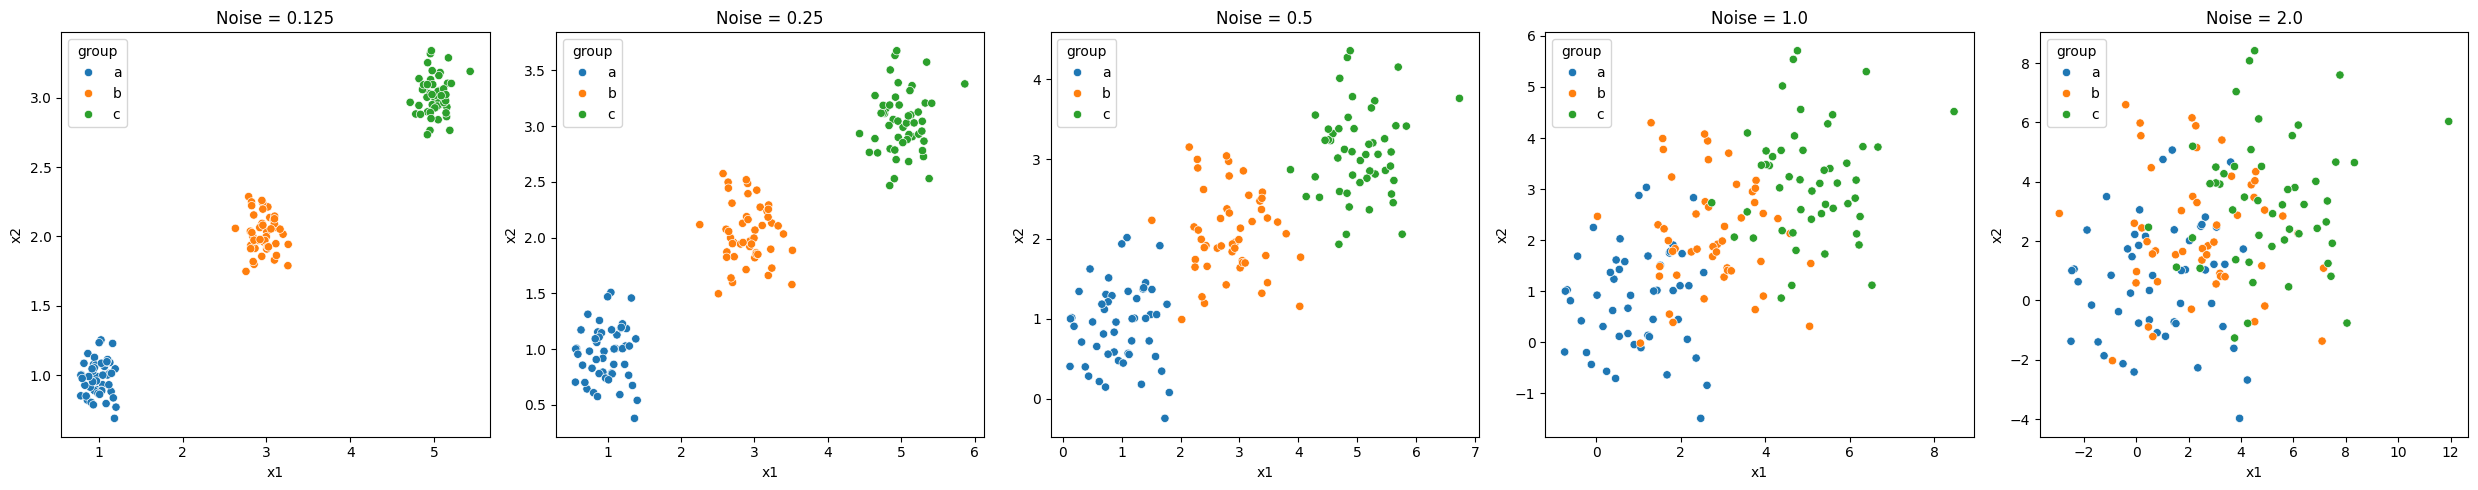

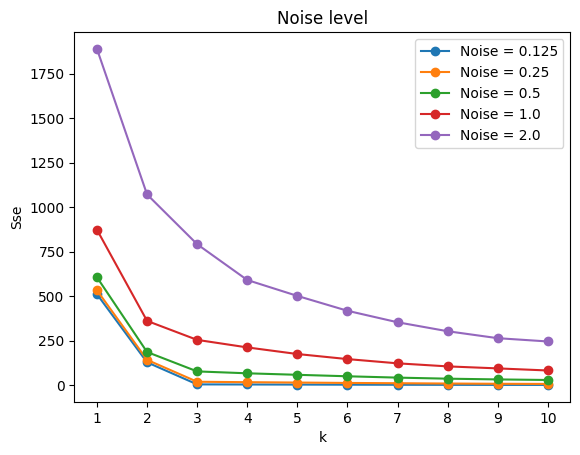

In [8]:
#Part 1
import matplotlib.pyplot as plt
import seaborn as sns

datasets = {'0.125': df0_125, '0.25': df0_25, '0.5': df0_5, '1.0': df1_0, '2.0': df2_0}

fig, axes = plt.subplots(1, 5, figsize=(25, 5))
for ax, (noise, d) in zip(axes, datasets.items()):
    sns.scatterplot(data=d, x='x1', y='x2', hue='group', ax=ax)
    ax.set_title(f'Noise = {noise}')
plt.tight_layout()
plt.show()

#Part 2
from sklearn.cluster import KMeans

k_values = range(1, 11)

# all the scree curves on one plot so the y-axis is the same
for noise, d in datasets.items():
    sse = []
    for k in k_values:
        model = KMeans(n_clusters=k, n_init=10, random_state=0)
        model.fit(d[['x1', 'x2']])
        sse.append(model.inertia_)
    plt.plot(k_values, sse, marker='o', label=f'Noise = {noise}')

plt.title('Noise level')
plt.xlabel('k')
plt.ylabel('Sse')
plt.xticks(k_values)
plt.legend()
plt.show()

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?

Yes: (included further cleaning in code)

2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?

The points form one long diagonal cloud from bottom left to top right, since countries that spend more in total also tend to spend more per person. There aren't really separate blobs with gaps between them, so k-means is basically slicing that diagonal into three tiers: low, middle, and high spenders. It's the dot in the very top right corner of the plot, at the max for total spending (1.0) and almost the max for spending per capita (0.99), in the high spending cluster (cluster 0). Cluster membership mostly follows how wealthy a country is. Rich countries like the US and Western Europe are high spenders, middle-income countries in Latin America, the Balkans, and South Asia are in the middle, and poorer countries, mostly in Africa, are low spenders.

3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?

The elbow is at k = 3 again. The clusters now group countries by how much they prioritize their military rather than by wealth, so the high share cluster mixes countries like the US, Russia, and Saudi Arabia with poorer ones like Chad and Niger. Compared to part 2, rich and poor countries are now mixed together instead of being sorted by income. Western Europe drops to the middle cluster, and the US is still in the top cluster but no longer the most extreme point.

4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?

The elbow isn't as clear this time, but I used k = 3 to match the other parts. One cluster is wealthy countries that don't prioritize their military much, like Western Europe. Another is countries that spend a large share of their budget on the military, like the US and Russia. The last is low spenders, which are mostly poorer countries. Part 2 grouped countries by wealth, and part 3 grouped them by military priority. Using all four variables does both, so it can tell apart countries that spend a lot because they're rich from countries that spend a lot because they prioritize defense.

5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

Sort of, yes. The most useful thing was using all four variables, since it split countries that spend a lot because they're rich from ones that spend a lot because they really prioritize their military. You wouldn't catch that just looking at total spending.But the clusters weren't super distinct. The data was basically one big cloud, so k-means was just cutting it into tiers, and the elbows weren't very clear. For the most part, it confirmed stuff you'd already expect, like richer countries spending more, instead of showing anything surprising.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Grady Berlik

**Date:** 10/12/26

(148, 7)


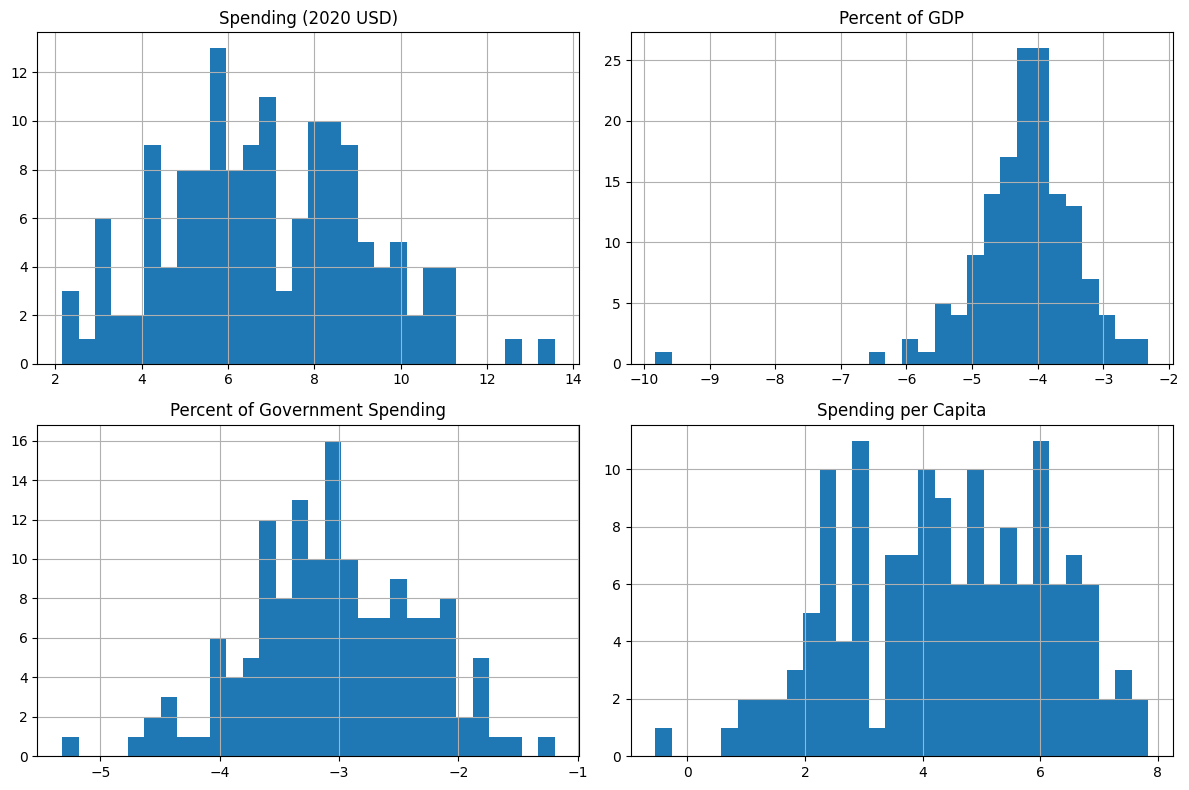

           Spending (2020 USD)  Percent of GDP  \
Country                                          
Zimbabwe              2.154370       -9.826457   
Mauritius             2.916602       -6.417453   
Ireland               7.042654       -5.851745   

           Percent of Government Spending  Spending per Capita  
Country                                                         
Zimbabwe                        -3.966402            -0.544504  
Mauritius                       -5.319248             2.676012  
Ireland                         -4.633529             5.445693  
(147, 4)
       Spending (2020 USD)  Percent of GDP  Percent of Government Spending  \
count               147.00          147.00                          147.00   
mean                  0.00           -0.00                            0.00   
std                   1.00            1.00                            1.00   
min                  -2.02           -3.31                           -3.20   
25%                  -0.7

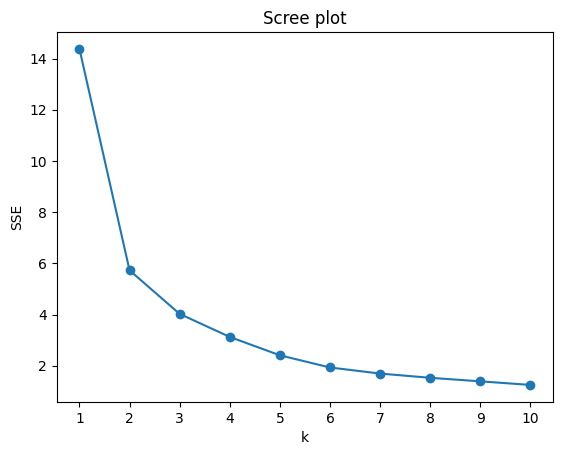

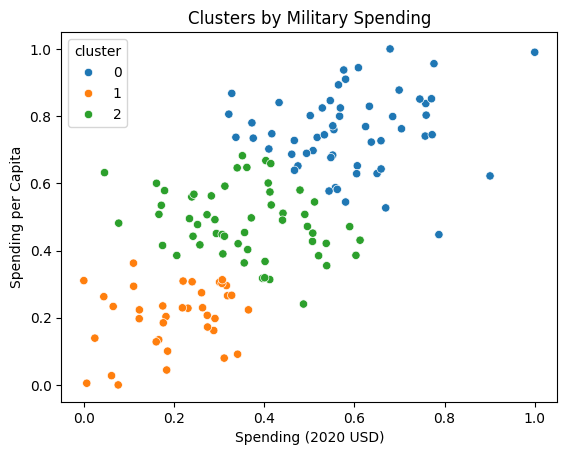

cluster                                       0       1         2
Spending (2020 USD)            count      56.00   37.00     54.00
                               mean    33174.91  179.49   1524.25
                               std    108159.10  163.35   2250.96
                               min       405.79   11.28     18.81
                               25%      3198.03   44.35    208.11
                               50%      6330.48  128.92    616.51
                               75%     20147.55  288.26   1543.47
                               max    778397.20  659.31  10394.50
Percent of GDP                 count      56.00   37.00     54.00
                               mean        0.03    0.01      0.02
                               std         0.02    0.01      0.01
                               min         0.01    0.00      0.00
                               25%         0.01    0.01      0.01
                               50%         0.02    0.01      0.01
                               75%         0.03    0.02      0.02
                               max         0.10    0.03      0.05
Percent of Government Spending count      56.00   37.00     54.00
                               mean        0.07    0.05      0.06
                               std         0.05    0.03      0.05
                               min         0.01    0.00      0.01
                               25%         0.03    0.02      0.03
                               50%         0.05    0.04      0.05
                               75%         0.11    0.06      0.09
                               max         0.23    0.16      0.30
Spending per Capita            count      56.00   37.00     54.00
                               mean      617.93   11.57     86.49
                               std       537.41    6.45     62.74
                               min        52.85    2.31     12.46
                               25%       273.06    6.13     42.95
                               50%       427.10   11.04     66.10
                               75%       774.78   15.76    117.70
                               max      2520.40   29.18    273.04

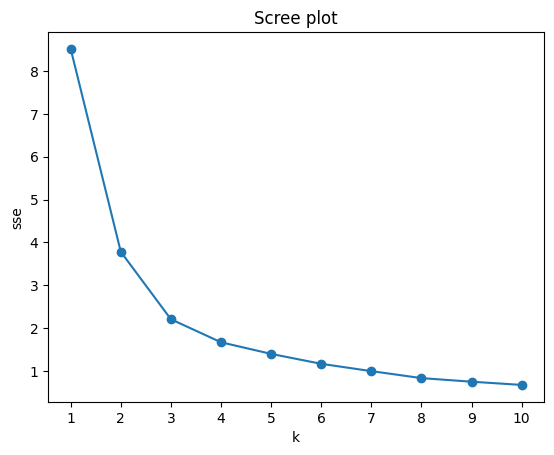

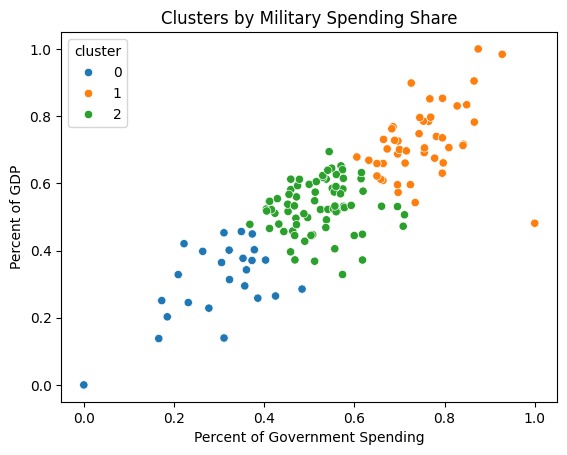

cluster                                       0       1         2
Spending (2020 USD)            count      56.00   37.00     54.00
                               mean    33174.91  179.49   1524.25
                               std    108159.10  163.35   2250.96
                               min       405.79   11.28     18.81
                               25%      3198.03   44.35    208.11
                               50%      6330.48  128.92    616.51
                               75%     20147.55  288.26   1543.47
                               max    778397.20  659.31  10394.50
Percent of GDP                 count      56.00   37.00     54.00
                               mean        0.03    0.01      0.02
                               std         0.02    0.01      0.01
                               min         0.01    0.00      0.00
                               25%         0.01    0.01      0.01
                               50%         0.02    0.01      0.01
                               75%         0.03    0.02      0.02
                               max         0.10    0.03      0.05
Percent of Government Spending count      56.00   37.00     54.00
                               mean        0.07    0.05      0.06
                               std         0.05    0.03      0.05
                               min         0.01    0.00      0.01
                               25%         0.03    0.02      0.03
                               50%         0.05    0.04      0.05
                               75%         0.11    0.06      0.09
                               max         0.23    0.16      0.30
Spending per Capita            count      56.00   37.00     54.00
                               mean      617.93   11.57     86.49
                               std       537.41    6.45     62.74
                               min        52.85    2.31     12.46
                               25%       273.06    6.13     42.95
                               50%       427.10   11.04     66.10
                               75%       774.78   15.76    117.70
                               max      2520.40   29.18    273.04

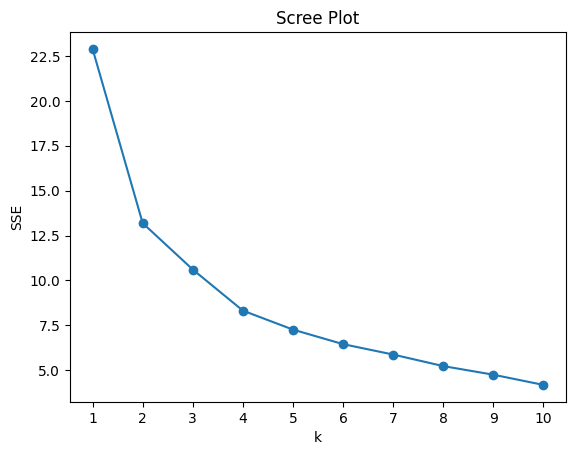

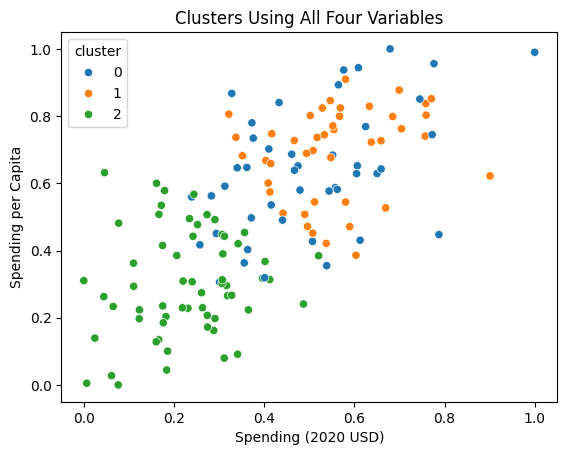

cluster                                         0            1          2
Spending (2020 USD)            count      44.0000      43.0000    60.0000
                               mean    27128.0320   17059.1014   326.1878
                               std    117207.9844   40765.5178   590.6964
                               min       162.3734     405.7905    11.2793
                               25%       692.3071    2712.4037    70.8593
                               50%      2297.0324    4980.4281   158.7322
                               75%      9775.8509   13402.0045   346.8208
                               max    778397.2000  257973.4298  3732.6737
Percent of GDP                 count      44.0000      43.0000    60.0000
                               mean        0.0351       0.0147     0.0121
                               std         0.0183       0.0053     0.0061
                               min         0.0117       0.0029     0.0016
                               25%         0.0242       0.0105     0.0075
                               50%         0.0306       0.0142     0.0114
                               75%         0.0408       0.0192     0.0159
                               max         0.0985       0.0281     0.0284
Percent of Government Spending count      44.0000      43.0000    60.0000
                               mean        0.1156       0.0337     0.0425
                               std         0.0471       0.0118     0.0215
                               min         0.0515       0.0097     0.0049
                               25%         0.0858       0.0260     0.0287
                               50%         0.1077       0.0325     0.0394
                               75%         0.1306       0.0443     0.0528
                               max         0.3030       0.0565     0.0936
Spending per Capita            count      44.0000      43.0000    60.0000
                               mean      452.0401     413.5653    33.8249
                               std       636.2185     307.6162    39.5787
                               min        19.6558      34.3186     2.3135
                               25%        74.0058     141.4627     9.5054
                               50%       194.9557     374.9433    18.1632
                               75%       442.3191     625.1512    45.5643
                               max      2520.3985    1341.0589   191.9809

In [29]:
# Your Phase 1 solution to the problem goes here.

#Part 1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('/content/SIPRI Military Expenditure Database.csv')

df = df[df['Year'] == 2020].dropna()
print(df.shape)

#drop index and year since it's not helpful as 2020 is the only year
df = df.drop(columns=['index', 'Year']).set_index('Country')

#Yes, more cleaning is required:

#all four variables are really right-skewed, so log them
df = np.log(df)

# check the Distributions after logging
df.hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

# one point is way off by itself in Percent of GDP, so find it
print(df.nsmallest(3, 'Percent of GDP'))

# it's Zimbabwe I looked at the data and it looks like a data error so I'll drop it
df = df.drop('Zimbabwe')

# put all four variables on the same scale
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(df), index=df.index, columns=df.columns)

print(X.shape)
print(X.describe().round(2))




#Part 2
from sklearn.cluster import KMeans
import seaborn as sns

#max-min normalize the two spending variables (these are already logged from part 1)
cols = ['Spending (2020 USD)', 'Spending per Capita']
Z = (df[cols] - df[cols].min()) / (df[cols].max() - df[cols].min())

#making scree plot
sse = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=0)
    model.fit(Z)
    sse.append(model.inertia_)

plt.plot(range(1, 11), sse, marker='o')
plt.title('Scree plot')
plt.xlabel('k')
plt.ylabel('SSE')
plt.xticks(range(1, 11))
plt.show()

# fit k-means with k= 3
kmeans = KMeans(n_clusters=3, n_init=10, random_state=0)
Z['cluster'] = kmeans.fit_predict(Z[cols])

sns.scatterplot(data=Z, x='Spending (2020 USD)', y='Spending per Capita', hue='cluster', palette='tab10')
plt.title('Clusters by Military Spending')
plt.show()

#describes table by cluster using the original values so that they're easier to read
results = np.exp(df)
results['cluster'] = Z['cluster']
results.groupby('cluster').describe().T.round(2)

display(results.groupby('cluster').describe().T.round(2))

#Part 3
cols2 = ['Percent of Government Spending', 'Percent of GDP']
Z2 = (df[cols2] - df[cols2].min()) / (df[cols2].max() - df[cols2].min())

#scree plot
sse2 = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=0)
    model.fit(Z2)
    sse2.append(model.inertia_)

plt.plot(range(1, 11), sse2, marker='o')
plt.title('Scree plot')
plt.xlabel('k')
plt.ylabel('sse')
plt.xticks(range(1, 11))
plt.show()

# fit k-means with k = 3
kmeans2 = KMeans(n_clusters=3, n_init=10, random_state=0)
Z2['cluster'] = kmeans2.fit_predict(Z2[cols2])

sns.scatterplot(data=Z2, x='Percent of Government Spending', y='Percent of GDP', hue='cluster', palette='tab10')
plt.title('Clusters by Military Spending Share')
plt.show()

# describe table by cluster, using the original (unlogged) values
results2 = np.exp(df)
results2['cluster'] = Z2['cluster']
results2.groupby('cluster').describe().T.round(4)

display(results.groupby('cluster').describe().T.round(2))

#Part 4
cols4 = ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']

Z4 = (df[cols4] - df[cols4].min()) / (df[cols4].max() - df[cols4].min())

# scree plot
sse4 = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=0)
    model.fit(Z4)
    sse4.append(model.inertia_)

plt.plot(range(1, 11), sse4, marker='o')
plt.title('Scree Plot')
plt.xlabel('k')
plt.ylabel('SSE')
plt.xticks(range(1, 11))
plt.show()

# fit k-means with k
kmeans4 = KMeans(n_clusters=3, n_init=10, random_state=0)
Z4['cluster'] = kmeans4.fit_predict(Z4[cols4])

sns.scatterplot(data=Z4, x='Spending (2020 USD)', y='Spending per Capita', hue='cluster', palette='tab10')
plt.title('Clusters Using All Four Variables')
plt.show()

results4 = np.exp(df)
results4['cluster'] = Z4['cluster']
results4.groupby('cluster').describe().T.round(4)





## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:**
- **AI tool and model used:**

### *Prompts used

1. [Past prompt here]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]